In [50]:
# install github clone - allows for easy cloning of subdirectories
from pathlib import Path 

# clone datasets
if not Path('chapter_8_datasets').is_dir():
    !ghclone https://github.com/neonwatty/machine-learning-refined-notes-assets/tree/main/notes/8_Linear_unsupervised_learning/chapter_8_datasets
else:
    print('chapter_8_datasets already cloned!')

# clone library subdirectory
if not Path('chapter_8_library').is_dir():
    !ghclone https://github.com/neonwatty/machine-learning-refined-notes-assets/tree/main/notes/8_Linear_unsupervised_learning/chapter_8_library
else:
    print('chapter_8_library already cloned!')

# clone images
if not Path('chapter_8_images').is_dir():
    !ghclone https://github.com/neonwatty/machine-learning-refined-notes-assets/tree/main/notes/8_Linear_unsupervised_learning/chapter_8_images
else:
    print('chapter_8_images already cloned!')

# clone videos
if not Path('chapter_8_videos').is_dir():
    !ghclone https://github.com/neonwatty/machine-learning-refined-notes-assets/tree/main/notes/8_Linear_unsupervised_learning/chapter_8_videos
else:
    print('chapter_8_videos already cloned!')

## run universally whether in collab or local ##
# append path for local library, data, and image import
import sys
sys.path.append('./chapter_8_library') 
sys.path.append('./chapter_8_images') 
sys.path.append('./chapter_8_datasets') 

# import section helper
import section_8_3_helpers

# dataset paths
dataset_path_1 = 'chapter_8_datasets/2d_span_data.csv'
dataset_path_2 = 'chapter_8_datasets/3d_span_data.csv'

# image paths
image_path_1 = "chapter_8_images/pca_classic.png"
image_path_2 = "chapter_8_images/Fig_9_7.png"

# standard imports
import matplotlib.pyplot as plt
from IPython.display import Image
import autograd.numpy as np
from matplotlib import gridspec

# this is needed to compensate for matplotlib notebook's tendancy to blow up images when plotted inline
%matplotlib inline
from matplotlib import rcParams
rcParams['figure.autolayout'] = True

%load_ext autoreload
%autoreload 2

chapter_8_datasets already cloned!
chapter_8_library already cloned!
chapter_8_images already cloned!
chapter_8_videos already cloned!
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [51]:
# here the weight matrices are loaded in a single list w = [C,W]
def least_squares(w):  
    # strip off C and W parameters
    C = w[0]
    W = w[1]
    
    # compute the least squares cost
    cost = np.sum((np.dot(C,W) - X)**2)
    return cost/float(X.shape[1])

In [53]:
# load in dataset
X_original = np.loadtxt(dataset_path_2,delimiter=',')

# center data
X_means = np.mean(X_original,axis=1)[:,np.newaxis]
X = X_original - X_means

# run gradient descent to minimize the Least Squares cost for linear regression
g = least_squares; max_its = 100; alpha_choice = 10**(0)

# set up initialization
scale = 0.1
C = scale*np.random.randn(3,2)
W = scale*np.random.randn(2,100)
w = [C,W]

# run gradient descent
weight_history,cost_history = section_8_3_helpers.gradient_descent(g,alpha_choice,max_its,w)

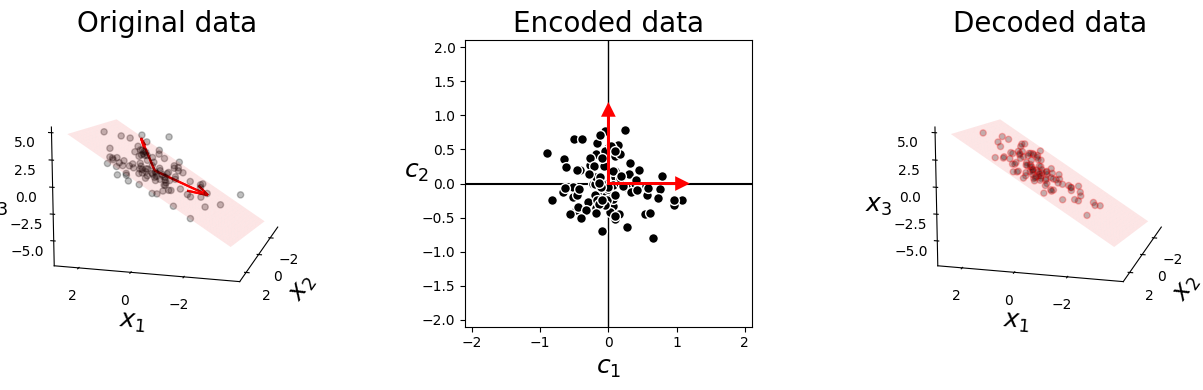

In [54]:
# produce visuals
C = weight_history[-1][0]
view = [15,105]
section_8_3_helpers.project_data_from_3d_to_2d(X,C,view)

In [55]:
import pandas as pd
X = np.loadtxt(dataset_path_1,delimiter=',')
X_mean = X.mean(axis=1, keepdims=True)   # shape (2, 1)
X = X - X_mean 

In [56]:
import numpy as np
from autograd import grad 

def g(C):
    return np.sum((np.dot(C, np.dot(C.T, X)) - X)**2) / float(X.shape[1])

# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def gradient_descent(g,alpha,max_its,w):
    # compute gradient module using autograd
    gradient = grad(g)

    # run the gradient descent loop
    weight_history = [w]           # container for weight history
    cost_history = [g(w)]          # container for corresponding cost function history
    for k in range(max_its):
        # evaluate the gradient, store current weights and cost function value
        grad_eval = gradient(w)

        # take gradient descent step
        w = w - alpha*grad_eval
        
        # record weight and cost
        weight_history.append(w)
        cost_history.append(g(w))
    return weight_history, cost_history

# parameters for gradient descent
max_its = 1000
n, p = X.shape
K = 1          
alpha = 0.1

C = 0.1 * np.random.randn(n, K)
alpha = 0.01
weight_history, cost_history = gradient_descent(g,alpha,max_its,C)

In [57]:
C_opt = weight_history[-1]
C_opt

array([[ 0.64634856],
       [-0.7630423 ]])

The optimal C is [-0.75371563, -0.6572007 ]

## Visualisation

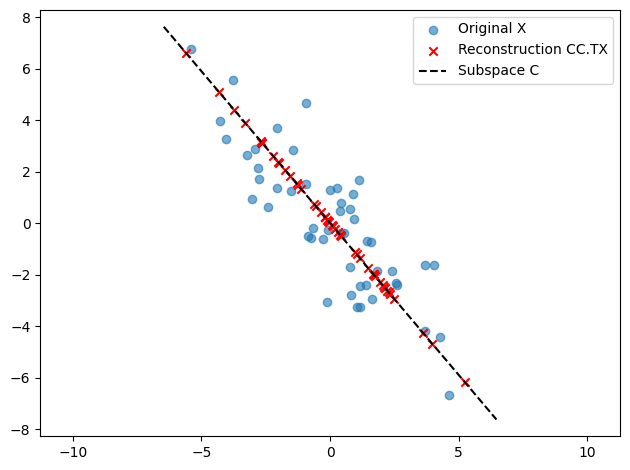

In [58]:
import matplotlib.pyplot as plt

X_hat = C_opt @ C_opt.T @ X 

plt.scatter(X[0], X[1], label='Original X', alpha=0.6)
plt.scatter(X_hat[0], X_hat[1], label='Reconstruction CC.TX', marker='x', c='red')

# tracer la direction apprise
t = np.linspace(-10, 10, 100)
line = C_opt * t
plt.plot(line[0], line[1], 'k--', label='Subspace C')

plt.legend()
plt.axis('equal')
plt.show()